# Correlación individual de verano e invierno: pozos de Sucre

Este notebook usa el cruce individual entre las mediciones de NE y los índices ambientales. Cada fila representa una medición de NE asociada con la fecha más cercana de precipitación, NDVI, EVI y NDWI para su municipio. No se promedian los valores de NE.

Se calculan matrices separadas para verano e invierno, coeficientes de Pearson y Spearman, valores p, corrección FDR, regresiones lineales e indicadores descriptivos. La base completa se conserva para sensibilidad.

In [34]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from IPython.display import display
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid")

ARCHIVO_CRUCE = Path("cruce_NE_indices_individual.xlsx")

# Cambia esta lista para analizar otro pozo o varios pozos.
POZOS_ANALIZAR = ["Finca el socorro (Ovejas) - # 44-II-D-PO-02"]
# Ejemplo para incluir los dos pozos de Ovejas:
# POZOS_ANALIZAR = [
#     "Finca el socorro (Ovejas) - # 44-II-D-PO-02",
#     "Ovejas - # 44-II-D-PO-14",
# ]

VARS = ["Precipitacion_mm", "NDVI", "EVI", "NDWI"]
OBJETIVO = "NE"
COLUMNAS_ANALISIS = VARS + [OBJETIVO]

if not ARCHIVO_CRUCE.exists():
    raise FileNotFoundError(f"No se encontró el cruce individual: {ARCHIVO_CRUCE.resolve()}")

verano = pd.read_excel(ARCHIVO_CRUCE, sheet_name="Verano")
invierno = pd.read_excel(ARCHIVO_CRUCE, sheet_name="Invierno")
base_completa = pd.concat([verano, invierno], ignore_index=True)

def preparar_cruce(datos):
    datos = datos.copy()
    if POZOS_ANALIZAR:
        datos = datos[datos["pozo"].isin(POZOS_ANALIZAR)].copy()
    datos["Temporada_corta"] = np.where(
        datos["Temporada"].astype("string").str.contains("Verano", case=False, na=False), "Verano", "Invierno"
    )
    datos["Fecha_NE"] = pd.to_datetime(datos["Fecha_NE"], errors="coerce")
    datos["Fecha"] = datos["Fecha_NE"]
    datos["anio"] = datos["Fecha_NE"].dt.year
    datos["Imputado"] = pd.to_numeric(datos["Imputado"], errors="coerce").fillna(0).astype(int)
    datos["temporada_incompleta"] = 0
    datos["n_observadas"] = 1
    datos["n_imputadas"] = datos["Imputado"]
    return datos.sort_values(["pozo", "Fecha_NE"]).reset_index(drop=True)

raw_completa = preparar_cruce(base_completa)
raw = raw_completa[raw_completa["Imputado"].eq(0)].copy()
raw = raw.dropna(subset=COLUMNAS_ANALISIS).reset_index(drop=True)

if raw.empty:
    raise ValueError("El filtro POZOS_ANALIZAR no encontró registros en la base estricta.")
if raw[COLUMNAS_ANALISIS].isna().any().any():
    raise ValueError("Hay valores faltantes en la base estricta para las variables requeridas.")

print(f"Pozos seleccionados: {POZOS_ANALIZAR}")
print(f"Cruce cercano completo: {len(raw_completa)} registros | Base observada para análisis: {len(raw)} registros")
print("Cada fila representa una medición individual de NE; no se promedian los valores.")
print(f"Archivo de cruce: {ARCHIVO_CRUCE.resolve()}")
display(raw.head())

Pozos seleccionados: ['Finca el socorro (Ovejas) - # 44-II-D-PO-02']
Cruce cercano completo: 52 registros | Base observada para análisis: 42 registros
Cada fila representa una medición individual de NE; no se promedian los valores.
Archivo de cruce: C:\Users\alexd\Documents\Proyecto correlacion\NoteBook-Correlacion\correlacion_ovejas_ml\cruce_NE_indices_individual.xlsx


,Fecha_NE_raw,NE,Imputado,Fecha_NE,pozo,Ciudad,Fecha_indice,Temporada_indice,Precipitacion_mm,NDVI,...,Diferencia_dias,Diferencia_dias_firmada,Cruce_recomendado,Temporada,Temporada_corta,Fecha,anio,temporada_incompleta,n_observadas,n_imputadas
0,2010-03-17,10.27436,0,2010-03-17,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2010-01-01,Verano (seco) - Febrero,0,0.603906,...,75,75,True,Verano (seco) - Febrero,Verano,2010-03-17,2010,0,1,0
1,2010-12-19,10.23000,0,2010-12-19,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2011-02-01,Verano (seco) - Febrero,17,0.645200,...,44,-44,True,Verano (seco) - Febrero,Verano,2010-12-19,2010,0,1,0
2,2011-08-11,10.20000,0,2011-08-11,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2011-10-01,Invierno (lluvioso) - Octubre,471,0.938900,...,51,-51,True,Invierno (lluvioso) - Octubre,Invierno,2011-08-11,2011,0,1,0
3,2012-03-17,10.19000,0,2012-03-17,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2012-03-01,Verano (seco) - Febrero,7,0.459089,...,16,16,True,Verano (seco) - Febrero,Verano,2012-03-17,2012,0,1,0
4,2012-07-23,10.11000,0,2012-07-23,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2012-11-01,Invierno (lluvioso) - Octubre,123,0.814425,...,101,-101,True,Invierno (lluvioso) - Octubre,Invierno,2012-07-23,2012,0,1,0


## 1. Auditoría descriptiva

Se conserva la información original y se verifica la cantidad de registros por temporada y por condición de imputación antes de calcular los coeficientes.


In [35]:
auditoria = pd.DataFrame({
    "Base": ["Completa", "Estricta ML"],
    "Registros": [len(raw_completa), len(raw)],
    "Pozos": [raw_completa["pozo"].nunique(), raw["pozo"].nunique()],
    "Imputados": [int(raw_completa["Imputado"].eq(1).sum()), int(raw["Imputado"].eq(1).sum())],
    "Periodos incompletos": [int(raw_completa["temporada_incompleta"].sum()), int(raw["temporada_incompleta"].sum())],
    "Año mínimo": [raw_completa["anio"].min(), raw["anio"].min()],
    "Año máximo": [raw_completa["anio"].max(), raw["anio"].max()],
})
display(auditoria)
display(raw[COLUMNAS_ANALISIS].describe().T.round(4))

,Base,Registros,Pozos,Imputados,Periodos incompletos,Año mínimo,Año máximo
0,Completa,52,1,10,0,2010,2024
1,Estricta ML,42,1,0,0,2010,2024


,count,mean,std,min,25%,50%,75%,max
Precipitacion_mm,42.0,102.7143,131.0351,0.0000,7.2500,18.5000,185.0000,471.0000
NDVI,42.0,0.7040,0.1295,0.4591,0.6077,0.6586,0.8373,0.9389
EVI,42.0,0.5111,0.1676,0.2874,0.3911,0.4330,0.6775,0.7859
NDWI,42.0,0.1996,0.1437,-0.0653,0.0793,0.1742,0.3400,0.4598
NE,42.0,10.2116,0.6235,9.4200,9.7412,10.0450,10.5175,11.8000


## 2. Pearson y Spearman

- **Pearson** mide la asociación lineal.
- **Spearman** mide la asociación monotónica a partir de rangos.
- Los valores `p` se ajustan mediante FDR de Benjamini-Hochberg para controlar comparaciones múltiples.
- El tamaño muestral es pequeño y las observaciones tienen estructura temporal y estacional.

In [36]:
def calcular_correlaciones(datos, nombre_serie):
    filas = []
    for variable in VARS:
        par = datos[[variable, OBJETIVO]].dropna()
        n = len(par)
        if n < 3:
            continue
        for metodo, funcion in [("Pearson", pearsonr), ("Spearman", spearmanr)]:
            resultado = funcion(par[variable], par[OBJETIVO])
            filas.append({"Serie": nombre_serie, "Variable": variable, "Metodo": metodo, "n": n, "r": resultado.statistic, "p": resultado.pvalue})
    return pd.DataFrame(filas)

def matriz_correlacion(datos, metodo):
    return datos[COLUMNAS_ANALISIS].corr(method=metodo).rename(columns={OBJETIVO: "NE"})

def ejecutar_tablas(datos, etiqueta):
    grupos = [("Global", datos)]
    grupos += [(temporada, datos[datos["Temporada_corta"] == temporada]) for temporada in ["Verano", "Invierno"]]
    return pd.concat([calcular_correlaciones(g, f"{etiqueta} - {nombre}") for nombre, g in grupos], ignore_index=True)

def ajustar_fdr(tabla, alpha=0.05):
    tabla = tabla.copy()
    p = tabla["p"].to_numpy(dtype=float)
    orden = np.argsort(p)
    ajustados = np.empty(len(p), dtype=float)
    acumulado = 1.0
    for posicion in range(len(p) - 1, -1, -1):
        rango = posicion + 1
        valor = p[orden[posicion]] * len(p) / rango
        acumulado = min(acumulado, valor)
        ajustados[orden[posicion]] = min(acumulado, 1.0)
    tabla["p_fdr"] = ajustados
    tabla["significativo_fdr"] = tabla["p_fdr"] < alpha
    return tabla

observados = raw.copy()
correlaciones_principales = ajustar_fdr(ejecutar_tablas(observados, "Observados sin imputar"))
correlaciones_todos = ajustar_fdr(ejecutar_tablas(raw_completa, "Todos los periodos"))

print("CORRELACIONES PRINCIPALES: BASE ESTRICTA")
display(correlaciones_principales.round(4))
print("SENSIBILIDAD: BASE COMPLETA")
display(correlaciones_todos.round(4))

CORRELACIONES PRINCIPALES: BASE ESTRICTA


,Serie,Variable,Metodo,n,r,p,p_fdr,significativo_fdr
0,Observados sin imputar - Global,Precipitacion_mm,Pearson,42,-0.0719,0.6511,0.7814,False
1,Observados sin imputar - Global,Precipitacion_mm,Spearman,42,-0.0765,0.6300,0.7814,False
2,Observados sin imputar - Global,NDVI,Pearson,42,-0.1357,0.3917,0.5875,False
3,Observados sin imputar - Global,NDVI,Spearman,42,-0.1662,0.2928,0.4684,False
4,Observados sin imputar - Global,EVI,Pearson,42,0.0507,0.7496,0.8178,False
5,Observados sin imputar - Global,EVI,Spearman,42,-0.1094,0.4902,0.6632,False
6,Observados sin imputar - Global,NDWI,Pearson,42,-0.0414,0.7945,0.8291,False
7,Observados sin imputar - Global,NDWI,Spearman,42,-0.1077,0.4974,0.6632,False
8,Observados sin imputar - Verano,Precipitacion_mm,Pearson,25,-0.2621,0.2056,0.3796,False
9,Observados sin imputar - Verano,Precipitacion_mm,Spearman,25,-0.2829,0.1706,0.3669,False


SENSIBILIDAD: BASE COMPLETA


,Serie,Variable,Metodo,n,r,p,p_fdr,significativo_fdr
0,Todos los periodos - Global,Precipitacion_mm,Pearson,52,-0.0880,0.5352,0.6116,False
1,Todos los periodos - Global,Precipitacion_mm,Spearman,52,-0.0579,0.6835,0.7456,False
2,Todos los periodos - Global,NDVI,Pearson,52,-0.1819,0.1969,0.3375,False
3,Todos los periodos - Global,NDVI,Spearman,52,-0.1962,0.1633,0.3016,False
4,Todos los periodos - Global,EVI,Pearson,52,-0.0069,0.9614,0.9614,False
5,Todos los periodos - Global,EVI,Spearman,52,-0.1323,0.3499,0.5248,False
6,Todos los periodos - Global,NDWI,Pearson,52,-0.1052,0.4579,0.5495,False
7,Todos los periodos - Global,NDWI,Spearman,52,-0.1499,0.2889,0.4622,False
8,Todos los periodos - Verano,Precipitacion_mm,Pearson,29,-0.1705,0.3764,0.5314,False
9,Todos los periodos - Verano,Precipitacion_mm,Spearman,29,-0.1558,0.4196,0.5494,False


## 3. Matrices de correlación

Las matrices permiten revisar la relación entre todas las variables ambientales y `NE`.


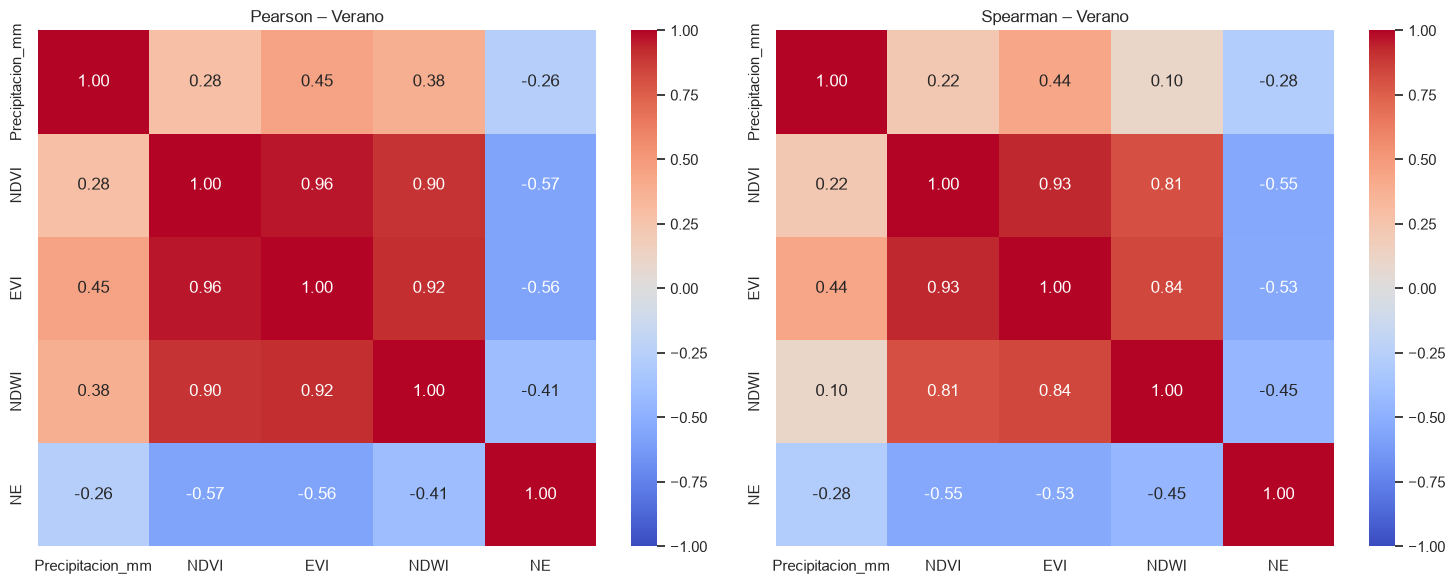

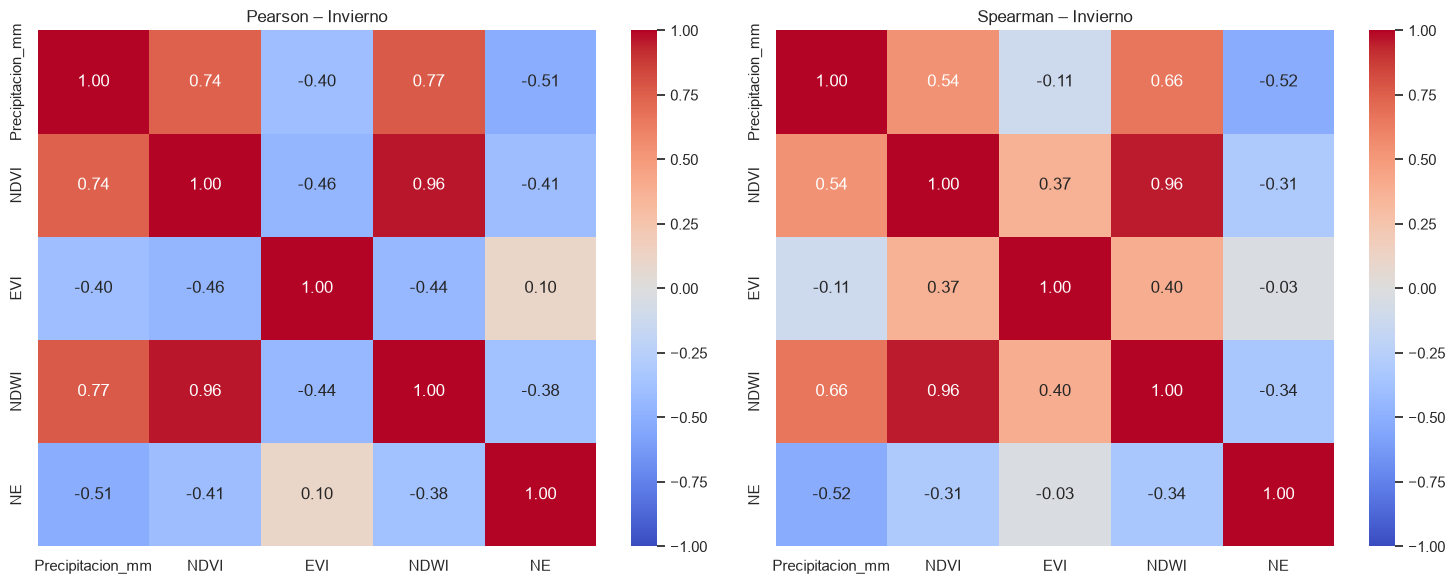

In [37]:
matrices = {}
for temporada in ["Verano", "Invierno"]:
    datos_temporada = observados[observados["Temporada_corta"].eq(temporada)]
    matrices[temporada] = {}
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, metodo in zip(axes, ["pearson", "spearman"]):
        matriz = matriz_correlacion(datos_temporada, metodo)
        matrices[temporada][metodo] = matriz
        sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
        ax.set_title(f"{metodo.title()} – {temporada}")
    plt.tight_layout()
    plt.show()

## 4. Relación de cada variable con el nivel estático


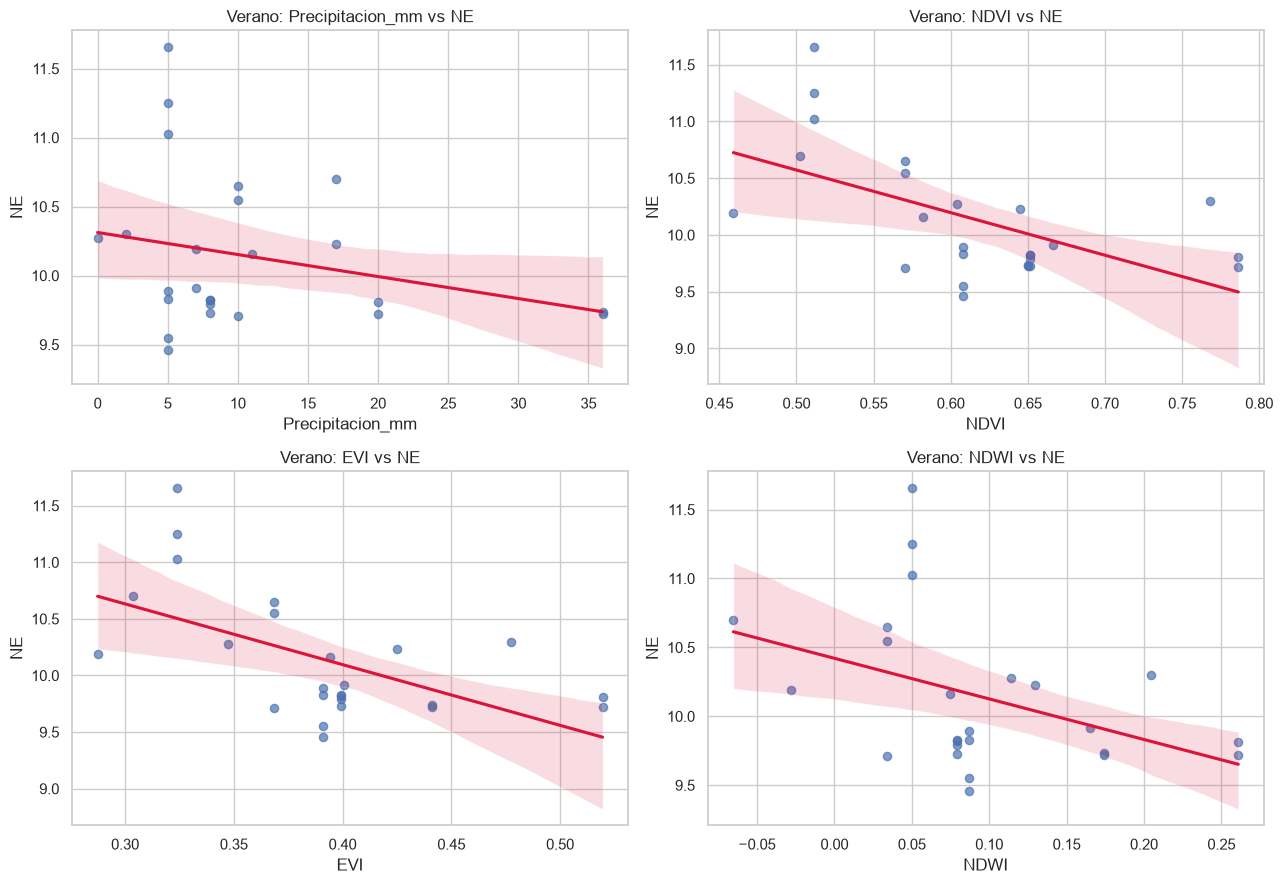

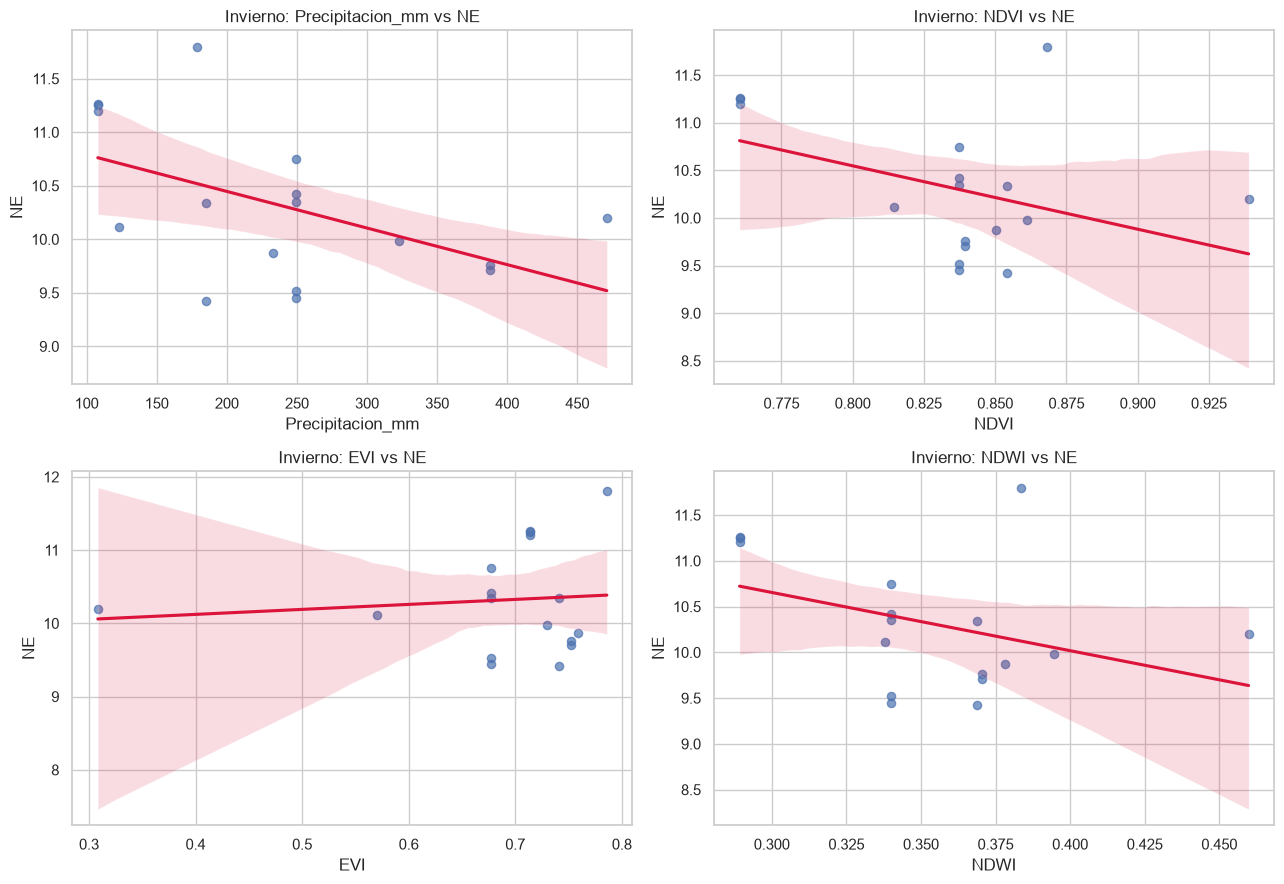

,Temporada,Variable,n,Pendiente,Intercepto,R2_regresion
0,Verano,Precipitacion_mm,25,-0.0160,10.3121,0.0687
1,Verano,NDVI,25,-3.7511,12.4475,0.3216
2,Verano,EVI,25,-5.3634,12.2412,0.3184
3,Verano,NDWI,25,-2.9469,10.4208,0.1701
4,Invierno,Precipitacion_mm,17,-0.0034,11.1311,0.2579
5,Invierno,NDVI,17,-6.6569,15.8727,0.1668
6,Invierno,EVI,17,0.6815,9.8494,0.0108
7,Invierno,NDWI,17,-6.3606,12.5622,0.1440


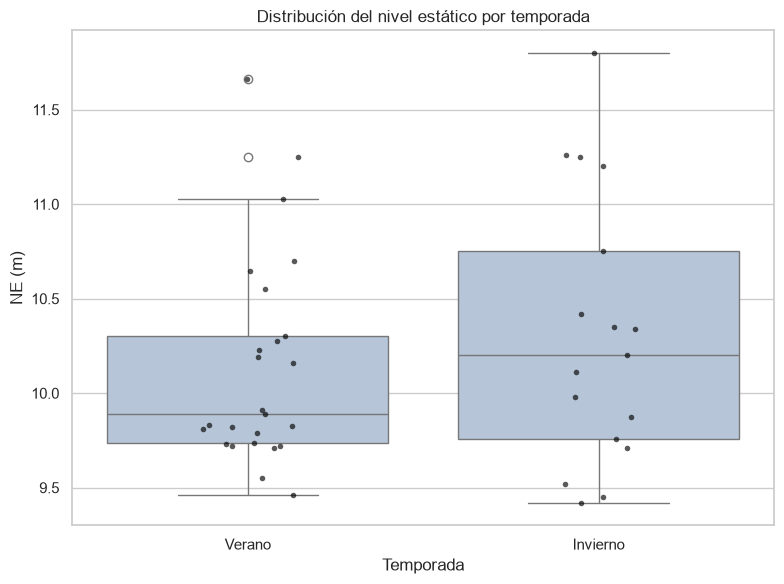

In [38]:
regresiones = []
for temporada in ["Verano", "Invierno"]:
    datos_temporada = observados[observados["Temporada_corta"].eq(temporada)]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, variable in zip(axes.ravel(), VARS):
        par = datos_temporada[[variable, OBJETIVO]].dropna()
        if len(par) >= 3:
            pendiente, intercepto = np.polyfit(par[variable], par[OBJETIVO], 1)
            pred = pendiente * par[variable] + intercepto
            r2 = r2_score(par[OBJETIVO], pred)
            regresiones.append({"Temporada": temporada, "Variable": variable, "n": len(par), "Pendiente": pendiente, "Intercepto": intercepto, "R2_regresion": r2})
        sns.regplot(data=par, x=variable, y=OBJETIVO, ax=ax, scatter_kws={"s": 35, "alpha": 0.7}, line_kws={"color": "crimson"})
        ax.set_title(f"{temporada}: {variable} vs NE")
        ax.set_xlabel(variable)
        ax.set_ylabel("NE")
    plt.tight_layout()
    plt.show()
regresiones = pd.DataFrame(regresiones)
display(regresiones.round(4))

# Diagrama de caja y bigotes para comparar la distribución del NE por temporada.
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=observados, x="Temporada_corta", y=OBJETIVO, order=["Verano", "Invierno"], ax=ax, color="lightsteelblue")
sns.stripplot(data=observados, x="Temporada_corta", y=OBJETIVO, order=["Verano", "Invierno"], ax=ax, color="black", alpha=0.65, jitter=0.15, size=4)
ax.set_title("Distribución del nivel estático por temporada")
ax.set_xlabel("Temporada")
ax.set_ylabel("NE (m)")
plt.tight_layout()
plt.show()

## 5. Exportación de resultados

Se guarda un Excel con la tabla limpia, las correlaciones principales, la sensibilidad con imputados y las matrices.


In [39]:
RUTA_SALIDA = Path("resultados_correlacion_ovejas.xlsx")
with pd.ExcelWriter(RUTA_SALIDA, engine="openpyxl") as writer:
    raw.to_excel(writer, sheet_name="Datos_leidos", index=False)
    observados.to_excel(writer, sheet_name="Datos_observados", index=False)
    correlaciones_principales.to_excel(writer, sheet_name="Pearson_Spearman", index=False)
    correlaciones_todos.to_excel(writer, sheet_name="Sensibilidad_imputados", index=False)
    regresiones.to_excel(writer, sheet_name="Regresiones", index=False)
    for temporada in ["Verano", "Invierno"]:
        matrices[temporada]["pearson"].to_excel(writer, sheet_name=f"Matriz_Pearson_{temporada}")
        matrices[temporada]["spearman"].to_excel(writer, sheet_name=f"Matriz_Spearman_{temporada}")
print(f"Resultados guardados en: {RUTA_SALIDA.resolve()}")

Resultados guardados en: C:\Users\alexd\Documents\Proyecto correlacion\NoteBook-Correlacion\correlacion_ovejas_ml\resultados_correlacion_ovejas.xlsx


## Interpretación inicial

Los coeficientes describen asociación, no causalidad. En este estudio `NE` es la profundidad o nivel estático del agua; por tanto, un aumento de `NE` significa mayor profundidad según la convención de la base. Cada fila corresponde a una medición individual de NE emparejada con el índice ambiental más cercano. Las matrices de verano e invierno deben interpretarse por separado y considerando la diferencia de días del emparejamiento.

## 6. Machine Learning exploratorio

Esta sección aplica la metodología de forma adaptada a la información disponible. El archivo contiene pocas observaciones y no tiene una frecuencia temporal regular, por lo que los retardos se interpretan como **observaciones anteriores disponibles**, no como meses exactos.

El objetivo es predecir la profundidad `NE`. Un valor predicho mayor representa agua más profunda. El modelo principal excluye los registros imputados y los resultados se consideran exploratorios.


In [40]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

serie_ml = raw.sort_values(["pozo", "Fecha"]).copy()
for variable in VARS:
    serie_ml[f"{variable}_retardo_1"] = serie_ml.groupby("pozo")[variable].shift(1)

datos_ml = serie_ml[serie_ml["Imputado"].eq(0)].dropna(
    subset=[OBJETIVO, *VARS, *[f"{v}_retardo_1" for v in VARS]]
).reset_index(drop=True)
CARACTERISTICAS = VARS + [f"{v}_retardo_1" for v in VARS]
X = datos_ml[CARACTERISTICAS]
y = datos_ml[OBJETIVO]
print(f"Registros disponibles para ML: {len(datos_ml)}")
print("Características:", CARACTERISTICAS)

Registros disponibles para ML: 41
Características: ['Precipitacion_mm', 'NDVI', 'EVI', 'NDWI', 'Precipitacion_mm_retardo_1', 'NDVI_retardo_1', 'EVI_retardo_1', 'NDWI_retardo_1']


In [41]:
RANDOM_STATE = 42


In [42]:
modelos = {
    "Base_promedio": DummyRegressor(strategy="mean"),
    "Random_Forest": RandomForestRegressor(n_estimators=200, max_depth=3, min_samples_leaf=2, random_state=RANDOM_STATE),
    "Gradient_Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, min_samples_leaf=2, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, objective="reg:squarederror", eval_metric="rmse", random_state=RANDOM_STATE, n_jobs=1),
}

n_splits = min(3, max(2, len(datos_ml) // 5))
tscv = TimeSeriesSplit(n_splits=n_splits)
metricas, predicciones = [], []
for nombre, modelo_base in modelos.items():
    y_real_total, y_pred_total = [], []
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
        modelo_base.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = modelo_base.predict(X.iloc[test_idx])
        y_real_total.extend(y.iloc[test_idx])
        y_pred_total.extend(pred)
        predicciones.extend([{"Modelo": nombre, "Fold": fold, "Fecha": datos_ml.iloc[i]["Fecha"], "NE_real": y.iloc[list(X.index).index(i)] if i in X.index else np.nan, "NE_predicho": p} for i, p in zip(datos_ml.iloc[test_idx].index, pred)])
    metricas.append({"Modelo": nombre, "n_prueba_total": len(y_real_total), "MAE_m": mean_absolute_error(y_real_total, y_pred_total), "RMSE_m": mean_squared_error(y_real_total, y_pred_total) ** 0.5, "R2": r2_score(y_real_total, y_pred_total)})
metricas_modelos = pd.DataFrame(metricas).sort_values("RMSE_m")
predicciones_ml = pd.DataFrame(predicciones)
print("MÉTRICAS DE VALIDACIÓN CRONOLÓGICA")
display(metricas_modelos.round(4))

MÉTRICAS DE VALIDACIÓN CRONOLÓGICA


,Modelo,n_prueba_total,MAE_m,RMSE_m,R2
3,XGBoost,30,0.4859,0.6374,0.1133
1,Random_Forest,30,0.5496,0.6982,-0.0637
0,Base_promedio,30,0.6180,0.7286,-0.1585
2,Gradient_Boosting,30,0.5422,0.7366,-0.1840


### Importancia de variables

La importancia se calcula de forma descriptiva ajustando el Random Forest con los registros disponibles. No debe interpretarse como evidencia causal y puede ser inestable debido al tamaño pequeño de la muestra.


,Variable,Importancia_RF
7,NDWI_retardo_1,0.2371
5,NDVI_retardo_1,0.1901
1,NDVI,0.1763
6,EVI_retardo_1,0.1263
2,EVI,0.0950
3,NDWI,0.0694
4,Precipitacion_mm_retardo_1,0.0534
0,Precipitacion_mm,0.0524


,Variable,Importancia_XGBoost
5,NDVI_retardo_1,0.1818
7,NDWI_retardo_1,0.1651
6,EVI_retardo_1,0.1487
1,NDVI,0.1276
0,Precipitacion_mm,0.1225
2,EVI,0.0995
4,Precipitacion_mm_retardo_1,0.0777
3,NDWI,0.0769


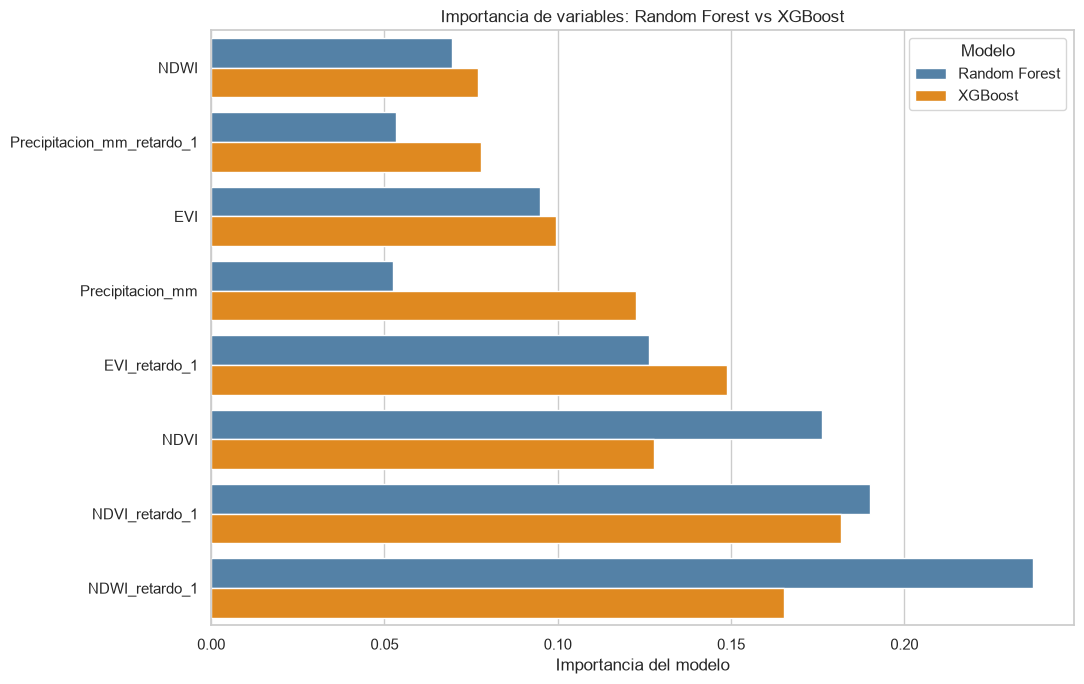

In [43]:
# Importancia de variables

# La importancia se calcula de forma descriptiva para Random Forest y XGBoost.
# No demuestra causalidad y puede ser inestable debido al tamaño pequeño de la muestra.

modelo_rf_final = modelos["Random_Forest"]
modelo_rf_final.fit(X, y)
importancia = pd.DataFrame({"Variable": CARACTERISTICAS, "Importancia_RF": modelo_rf_final.feature_importances_}).sort_values("Importancia_RF", ascending=False)
modelo_xgb_final = modelos["XGBoost"]
modelo_xgb_final.fit(X, y)
importancia_xgb = pd.DataFrame({"Variable": CARACTERISTICAS, "Importancia_XGBoost": modelo_xgb_final.feature_importances_}).sort_values("Importancia_XGBoost", ascending=False)
display(importancia.round(4))
display(importancia_xgb.round(4))

importancias_comparadas = pd.DataFrame({
    "Variable": CARACTERISTICAS,
    "Random Forest": modelo_rf_final.feature_importances_,
    "XGBoost": modelo_xgb_final.feature_importances_,
}).melt(id_vars="Variable", var_name="Modelo", value_name="Importancia")
orden_variables = importancias_comparadas.groupby("Variable")["Importancia"].max().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(
    data=importancias_comparadas,
    x="Importancia",
    y="Variable",
    hue="Modelo",
    order=orden_variables,
    palette={"Random Forest": "steelblue", "XGBoost": "darkorange"},
    ax=ax,
)
ax.set_title("Importancia de variables: Random Forest vs XGBoost")
ax.set_xlabel("Importancia del modelo")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Limitaciones de esta aplicación

- Solo hay pocos registros observados para entrenar y validar.
- Las fechas no forman una serie mensual regular; por eso `retardo_1` significa observación anterior, no necesariamente un mes.
- No se incorporan variables de bombeo, caudal, geometría del pozo, evapotranspiración ni características hidrogeológicas.
- Los resultados sirven para explorar patrones y preparar el flujo metodológico, no para operar predicciones del acuífero.


In [44]:
# Actualizar el archivo de resultados con la salida de ML.
with pd.ExcelWriter(RUTA_SALIDA, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    metricas_modelos.to_excel(writer, sheet_name="Metricas_ML", index=False)
    predicciones_ml.to_excel(writer, sheet_name="Predicciones_ML", index=False)
    importancia.to_excel(writer, sheet_name="Importancia_RF", index=False)
    importancia_xgb.to_excel(writer, sheet_name="Importancia_XGBoost", index=False)
    importancias_comparadas.to_excel(writer, sheet_name="Importancia_comparada", index=False)
print(f"Resultados de ML agregados en: {RUTA_SALIDA.resolve()}")

Resultados de ML agregados en: C:\Users\alexd\Documents\Proyecto correlacion\NoteBook-Correlacion\correlacion_ovejas_ml\resultados_correlacion_ovejas.xlsx


## 7. Alineación temporal y acumulados ambientales

La nueva base no contiene una serie mensual continua ni una fecha exacta para cada medición. Por ello, la alineación se realiza por pozo y por periodo estacional ordenado. `P_3_obs` y `P_6_obs` son acumulados de 3 y 6 observaciones estacionales disponibles, no acumulados mensuales exactos. Las variables con sufijo `_anterior` representan las condiciones del periodo estacional anterior del mismo pozo.

In [45]:
# Retardos y acumulados estacionales dentro de cada pozo.
serie_temporal = raw.sort_values(["pozo", "Fecha"]).copy()
grupo_pozo = serie_temporal.groupby("pozo", group_keys=False)

serie_temporal["P_actual"] = serie_temporal["Precipitacion_mm"]
serie_temporal["P_3_obs"] = grupo_pozo["Precipitacion_mm"].transform(lambda s: s.rolling(3, min_periods=3).sum())
serie_temporal["P_6_obs"] = grupo_pozo["Precipitacion_mm"].transform(lambda s: s.rolling(6, min_periods=6).sum())

for variable in ["Precipitacion_mm", "NDVI", "EVI", "NDWI"]:
    serie_temporal[f"{variable}_anterior"] = grupo_pozo[variable].shift(1)

precipitacion_anterior = grupo_pozo["Precipitacion_mm"].shift(1)
serie_temporal["P_3_obs_anteriores"] = precipitacion_anterior.groupby(serie_temporal["pozo"]).transform(lambda s: s.rolling(3, min_periods=3).sum())
serie_temporal["P_6_obs_anteriores"] = precipitacion_anterior.groupby(serie_temporal["pozo"]).transform(lambda s: s.rolling(6, min_periods=6).sum())

alineacion_temporal = serie_temporal.copy()
alineacion_temporal["Fecha_NE"] = alineacion_temporal["Fecha"]
alineacion_temporal["Dias_desde_referencia"] = 0

print(f"Periodos estacionales alineados: {len(alineacion_temporal)}")
display(alineacion_temporal.head())

Periodos estacionales alineados: 42


,Fecha_NE_raw,NE,Imputado,Fecha_NE,pozo,Ciudad,Fecha_indice,Temporada_indice,Precipitacion_mm,NDVI,...,P_actual,P_3_obs,P_6_obs,Precipitacion_mm_anterior,NDVI_anterior,EVI_anterior,NDWI_anterior,P_3_obs_anteriores,P_6_obs_anteriores,Dias_desde_referencia
0,2010-03-17,10.27436,0,2010-03-17,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2010-01-01,Verano (seco) - Febrero,0,0.603906,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2010-12-19,10.23000,0,2010-12-19,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2011-02-01,Verano (seco) - Febrero,17,0.645200,...,17,NaN,NaN,0.0,0.603906,0.347119,0.114291,NaN,NaN,0
2,2011-08-11,10.20000,0,2011-08-11,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2011-10-01,Invierno (lluvioso) - Octubre,471,0.938900,...,471,488.0,NaN,17.0,0.645200,0.424900,0.129700,NaN,NaN,0
3,2012-03-17,10.19000,0,2012-03-17,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2012-03-01,Verano (seco) - Febrero,7,0.459089,...,7,495.0,NaN,471.0,0.938900,0.308300,0.459800,488.0,NaN,0
4,2012-07-23,10.11000,0,2012-07-23,Finca el socorro (Ovejas) - # 44-II-D-PO-02,Ovejas,2012-11-01,Invierno (lluvioso) - Octubre,123,0.814425,...,123,601.0,NaN,7.0,0.459089,0.287387,-0.027919,495.0,NaN,0


In [46]:
# Correlaciones exploratorias entre NE y variables ambientales alineadas.
variables_alineadas = [
    "Precipitacion_mm", "P_actual", "P_3_obs", "P_6_obs",
    "P_3_obs_anteriores", "P_6_obs_anteriores",
    "NDVI", "EVI", "NDWI",
    "Precipitacion_mm_anterior", "NDVI_anterior",
    "EVI_anterior", "NDWI_anterior",
]

datos_alineados_observados = alineacion_temporal.loc[
    alineacion_temporal["Imputado"].eq(0),
    ["Fecha_NE", "NE", *variables_alineadas]
].dropna()

correlacion_lags = []
for variable in variables_alineadas:
    pares = datos_alineados_observados[["NE", variable]].dropna()
    if len(pares) < 3:
        continue
    for metodo, funcion in [("Pearson", pearsonr), ("Spearman", spearmanr)]:
        resultado = funcion(pares["NE"], pares[variable])
        correlacion_lags.append({
            "Variable": variable,
            "Metodo": metodo,
            "n": len(pares),
            "r": resultado.statistic,
            "p": resultado.pvalue,
        })

correlacion_lags = pd.DataFrame(correlacion_lags)
display(correlacion_lags.round(4))


,Variable,Metodo,n,r,p
0,Precipitacion_mm,Pearson,36,-0.0801,0.6425
1,Precipitacion_mm,Spearman,36,-0.0901,0.6013
2,P_actual,Pearson,36,-0.0801,0.6425
3,P_actual,Spearman,36,-0.0901,0.6013
4,P_3_obs,Pearson,36,-0.2254,0.1862
5,P_3_obs,Spearman,36,-0.3502,0.0363
6,P_6_obs,Pearson,36,-0.1887,0.2705
7,P_6_obs,Spearman,36,-0.2262,0.1847
8,P_3_obs_anteriores,Pearson,36,-0.1990,0.2447
9,P_3_obs_anteriores,Spearman,36,-0.2040,0.2327


In [47]:
# Agregar la alineación temporal y sus resultados al archivo de salida.
with pd.ExcelWriter(RUTA_SALIDA, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    alineacion_temporal.to_excel(writer, sheet_name="Alineacion_temporal", index=False)
    correlacion_lags.to_excel(writer, sheet_name="Correlacion_lags", index=False)
print(f"Alineación temporal agregada en: {RUTA_SALIDA.resolve()}")


Alineación temporal agregada en: C:\Users\alexd\Documents\Proyecto correlacion\NoteBook-Correlacion\correlacion_ovejas_ml\resultados_correlacion_ovejas.xlsx


## 8. ML con variables temporalmente alineadas

Esta versión del modelo utiliza las variables construidas mediante la fecha de `NE`: precipitación de la referencia, acumulados de 3 y 6 observaciones ambientales disponibles, y valores ambientales anteriores. Se reporta separada del modelo exploratorio simple para que la comparación sea transparente.


In [48]:
CARACTERISTICAS_ALINEADAS = [
    "P_actual", "P_3_obs", "P_6_obs",
    "P_3_obs_anteriores", "P_6_obs_anteriores",
    "NDVI", "EVI", "NDWI",
    "Precipitacion_mm_anterior", "NDVI_anterior",
    "EVI_anterior", "NDWI_anterior",
]

datos_ml_alineados = alineacion_temporal.loc[
    alineacion_temporal["Imputado"].eq(0),
    ["Fecha_NE", "NE", *CARACTERISTICAS_ALINEADAS]
].dropna().sort_values("Fecha_NE").reset_index(drop=True)

X_alineado = datos_ml_alineados[CARACTERISTICAS_ALINEADAS]
y_alineado = datos_ml_alineados[OBJETIVO]
print(f"Registros completos para ML alineado: {len(datos_ml_alineados)}")


Registros completos para ML alineado: 36


In [49]:
metricas_ml_alineado = []
if len(datos_ml_alineados) >= 8:
    n_splits_alineado = min(3, max(2, len(datos_ml_alineados) // 5))
    tscv_alineado = TimeSeriesSplit(n_splits=n_splits_alineado)
    modelos_alineados = {
        "Base_promedio_alineado": DummyRegressor(strategy="mean"),
        "Random_Forest_alineado": RandomForestRegressor(
            n_estimators=200, max_depth=3, min_samples_leaf=2, random_state=RANDOM_STATE
        ),
        "Gradient_Boosting_alineado": GradientBoostingRegressor(
            n_estimators=100, max_depth=2, learning_rate=0.05,
            min_samples_leaf=2, random_state=RANDOM_STATE
        ),
    }
    for nombre, modelo_base in modelos_alineados.items():
        reales, predichos = [], []
        for train_idx, test_idx in tscv_alineado.split(X_alineado):
            modelo_base.fit(X_alineado.iloc[train_idx], y_alineado.iloc[train_idx])
            pred = modelo_base.predict(X_alineado.iloc[test_idx])
            reales.extend(y_alineado.iloc[test_idx])
            predichos.extend(pred)
        metricas_ml_alineado.append({
            "Modelo": nombre,
            "n_prueba_total": len(reales),
            "MAE_m": mean_absolute_error(reales, predichos),
            "RMSE_m": mean_squared_error(reales, predichos) ** 0.5,
            "R2": r2_score(reales, predichos),
        })

metricas_ml_alineado = pd.DataFrame(metricas_ml_alineado)
display(metricas_ml_alineado.round(4))


,Modelo,n_prueba_total,MAE_m,RMSE_m,R2
0,Base_promedio_alineado,27,0.7174,0.8465,-0.5739
1,Random_Forest_alineado,27,0.7529,0.8612,-0.6289
2,Gradient_Boosting_alineado,27,0.7501,0.8718,-0.6693


In [50]:
with pd.ExcelWriter(RUTA_SALIDA, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    datos_ml_alineados.to_excel(writer, sheet_name="Datos_ML_alineados", index=False)
    metricas_ml_alineado.to_excel(writer, sheet_name="Metricas_ML_alineado", index=False)
print(f"ML alineado agregado en: {RUTA_SALIDA.resolve()}")


ML alineado agregado en: C:\Users\alexd\Documents\Proyecto correlacion\NoteBook-Correlacion\correlacion_ovejas_ml\resultados_correlacion_ovejas.xlsx


## 9. Cierre de la Fase 3: evaluación, interpretabilidad y limitaciones

Esta sección consolida la evaluación estadística y predictiva sin realizar despliegue operativo ni conclusiones definitivas. La importancia de variables se interpreta como evidencia descriptiva del modelo, no como causalidad hidrogeológica.

In [51]:
resumen_modelos = metricas_modelos.copy()
if not metricas_ml_alineado.empty:
    resumen_modelos = pd.concat([resumen_modelos, metricas_ml_alineado], ignore_index=True)
resumen_modelos = resumen_modelos.sort_values("RMSE_m", na_position="last").reset_index(drop=True)
print("RESUMEN DE EVALUACIÓN DE MODELOS")
display(resumen_modelos.round(4))

significativos = correlaciones_principales[correlaciones_principales["significativo_fdr"]].copy()
print(f"Correlaciones significativas después de FDR (alpha=0.05): {len(significativos)} de {len(correlaciones_principales)}")
if not significativos.empty:
    display(significativos[["Serie", "Variable", "Metodo", "n", "r", "p", "p_fdr"]].round(4))

print("LIMITACIONES METODOLÓGICAS")
print("- La muestra del pozo seleccionado es pequeña y los resultados son exploratorios.")
print("- Los retardos representan observaciones estacionales anteriores, no meses exactos.")
print("- Los índices y la precipitación son aproximaciones a escala municipal.")
print("- Las asociaciones y predicciones no demuestran causalidad hidrogeológica.")
print("- La validación alineada se reporta solo cuando hay suficientes periodos completos.")

RESUMEN DE EVALUACIÓN DE MODELOS


,Modelo,n_prueba_total,MAE_m,RMSE_m,R2
0,XGBoost,30,0.4859,0.6374,0.1133
1,Random_Forest,30,0.5496,0.6982,-0.0637
2,Base_promedio,30,0.6180,0.7286,-0.1585
3,Gradient_Boosting,30,0.5422,0.7366,-0.1840
4,Base_promedio_alineado,27,0.7174,0.8465,-0.5739
5,Random_Forest_alineado,27,0.7529,0.8612,-0.6289
6,Gradient_Boosting_alineado,27,0.7501,0.8718,-0.6693


Correlaciones significativas después de FDR (alpha=0.05): 4 de 24


,Serie,Variable,Metodo,n,r,p,p_fdr
10,Observados sin imputar - Verano,NDVI,Pearson,25,-0.5671,0.0031,0.037
11,Observados sin imputar - Verano,NDVI,Spearman,25,-0.5455,0.0048,0.037
12,Observados sin imputar - Verano,EVI,Pearson,25,-0.5643,0.0033,0.037
13,Observados sin imputar - Verano,EVI,Spearman,25,-0.5323,0.0062,0.037


LIMITACIONES METODOLÓGICAS
- La muestra del pozo seleccionado es pequeña y los resultados son exploratorios.
- Los retardos representan observaciones estacionales anteriores, no meses exactos.
- Los índices y la precipitación son aproximaciones a escala municipal.
- Las asociaciones y predicciones no demuestran causalidad hidrogeológica.
- La validación alineada se reporta solo cuando hay suficientes periodos completos.


### Alcance del notebook

El notebook queda cerrado en la **Fase 3: Validación Estadística, Evaluación de Modelos e Interpretabilidad**. La Fase 4 —SHAP, integración final de resultados, discusión definitiva y recomendaciones técnicas— queda pendiente para una etapa posterior.